<a href="https://colab.research.google.com/github/SinhaPushkar047/Langgraph/blob/main/Quadratic_Solver_conditional_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [35]:
class quad(TypedDict):
  a: int
  b: int
  c: int
  equation:str
  discriminant:float
  img: str
  equal: str
  distinct: str

In [36]:
def equation(state:quad)->quad:
  equation=f'{state['a']}x^2+{state['b']}x+{state['c']}'

  return {"equation":equation}

In [37]:
def check_disc(state:quad)->quad:
  disc=(state['b']**2)-(4*state['a']*state['c'])
  return {'discriminant':disc}

In [38]:
def img(state:quad)->quad:
  root_1=-state['b']/(2*state['a'])
  root_2=(state['discriminant']**0.5)/(2*state['a'])

  ans=f'Roots of this equation are imaginary {root_1}+i{root_2} and {root_1}-i{root_2}'

  return {'img':ans}

In [39]:
def equal(state:quad)->quad:
  root=-state['b']/(2*state['a'])

  ans=f'Roots are equal {root}'

  return {'equal':ans}

In [40]:
def distinct(state:quad)->quad:
  root_1=((-state['b'])+(state['discriminant']**0.5))/(2*state['a'])
  root_2=((-state['b'])-(state['discriminant']**0.5))/(2*state['a'])

  ans=f'Roots of this equation are real and distinct {root_1} and {root_2}'

  return {'distinct':distinct}

In [41]:
def check_condition(state:quad)-> Literal['img','equal','distinct']:
  if state['discriminant']>0:
    return "distinct"
  elif state['discriminant']==0:
    return 'equal'
  else:
    return 'img'

In [42]:
graph=StateGraph(quad)

graph.add_node('Form Equation',equation)
graph.add_node('Check Disc',check_disc)
graph.add_node('img',img)
graph.add_node('equal',equal)
graph.add_node('distinct',distinct)

graph.add_edge(START,'Form Equation')
graph.add_edge('Form Equation','Check Disc')

graph.add_conditional_edges('Check Disc',check_condition)

graph.add_edge('img',END)
graph.add_edge('equal',END)
graph.add_edge('distinct',END)

workflow=graph.compile()

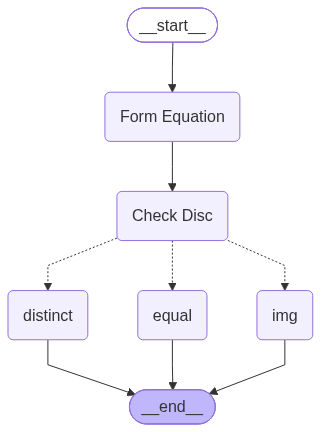

In [43]:
workflow

In [47]:
initital_state={'a':1,'b':1,'c':1}

In [48]:
final_state=workflow.invoke(initital_state)

In [49]:
final_state

{'a': 1,
 'b': 1,
 'c': 1,
 'equation': '1x^2+1x+1',
 'discriminant': -3,
 'img': 'Roots of this equation are imaginary -0.5+i(5.302876193624534e-17+0.8660254037844386j) and -0.5-i(5.302876193624534e-17+0.8660254037844386j)'}